# Data selection and cleaning: final saved database

**ASSUMPTIONS**
1. Remove columns that don't have a start/end day/month
2. `Total Damage, Adjusted ('000$)` as a proxy for event severity

In [100]:
%reload_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
import seaborn as sns
import calendar
import geopandas
import plotly.io as pio
import pysal
import numpy as np
from scipy import stats
from scipy.optimize import minimize
sns.set_theme(style='whitegrid')

In [128]:
df = pd.read_excel("../Data/natural_europe_19752025.xlsx")
columns = ['DisNo.',
           'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 
           'Event Name', 'ISO', 'Country', 'Subregion', 'Location',
           'Latitude', 
           'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 
           'End Year', 'End Month', 'End Day',
           "Total Damage, Adjusted ('000 US$)"]
df = df[columns].copy()
print(f"Total length: {len(df)}")

Total length: 2087


Because this is a historical database, some country names do not exist anymore. In the context of current design models for supply chains, we re-map old names to their current correspondance.

Beyond that, we are maping "Azores Islands" back to "Portugal". We remove countries that are now non-existant, that is: `[Soviet Union, Yugoslavia, Czechoslovakia]`

In [131]:
df = df[~df['Country'].isin(['Soviet Union', 'Yugoslavia', 'Czechoslovakia'])]

In [132]:
COUNTRY_REMAP = {
    "United Kingdom of Great Britain and Northern Ireland" : "United Kingdom",
    "Netherlands (Kingdom of the)" : "Netherlands",
    "Russian Federation" : "Russia",
    "Germany Federal Republic" : "Germany",
    "German Democratic Republic" : "Germany",
    "Czech Republic" : "Czechia",
    "Republic of Moldova" : "Moldova",
    "Azores Islands" : "Portugal",
    "Serbia Montenegro" : "Serbia",
}
df["Country"] = df["Country"].replace(COUNTRY_REMAP)
print(f"Total length: {len(df)}")

Total length: 2020


In [133]:
# We only keep events with complete start/end date information (Day/Month/Year)

df_events = df.dropna(subset = ["Start Month", "End Month", "Start Day", "End Day"])
df_events["Start Date"] = pd.to_datetime(
    df_events[["Start Year", "Start Month", "Start Day"]].rename(
        columns={"Start Year": "year", "Start Month": "month", "Start Day": "day"}), errors = "coerce")
df_events["End Date"] = pd.to_datetime(
    df_events[["End Year", "End Month", "End Day"]].rename(
        columns={"End Year": "year", "End Month": "month", "End Day": "day"}), errors = "coerce")

df_events["event_duration"] = (df_events["End Date"] - df_events["Start Date"]).dt.days + 1
df_events["event_duration"] = df_events["event_duration"].apply(lambda x : 1 if pd.isna(x) or x <= 0 else int(x))

print(f"The resulting database has {len(df_events)} records with complete date information")

The resulting database has 1694 records with complete date information


## Severity distribution fit

Number of datapoints with Total  Adjusted Damage: 665
FITTED LOGNORMAL PARAMETERS FOR ADJUSTED DAMAGE ('000 US$):
  scipy.stats.lognorm params: s=2.305361, loc=0.000000, scale=160811.583383
  Underlying normal:          mu=11.987989, sigma=2.305361
  Theoretical median:         160,811.58 ('000 US$)


,Feature,sigma (std of ln X),mu (mean of ln X),Median (exp(mu)),Log-Likelihood,AIC,BIC,KS Stat,p-value
0,Adjusted Damage ('000 US$),2.3054,11.988,160811.58,-9471.04,18946.08,18955.08,0.0624,0.0107


,Distribution,KS Stat,p-value
0,Lognormal,0.0624,0.0107


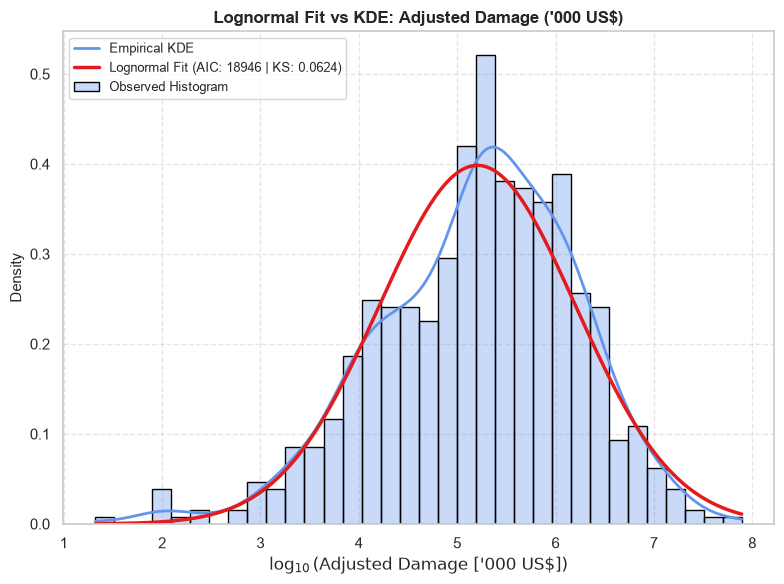

In [141]:
damage_data = df_events["Total Damage, Adjusted ('000 US$)"].dropna()
print(f"Number of datapoints with Total  Adjusted Damage: {len(damage_data)}")
x_vals = damage_data[damage_data > 0].to_numpy()
n = len(x_vals)

shape, loc, scale = stats.lognorm.fit(x_vals, floc=0)
params = (shape, loc, scale)

sigma = shape
mu = np.log(scale)
theoretical_median = scale

print("=" * 60)
print("FITTED LOGNORMAL PARAMETERS FOR ADJUSTED DAMAGE ('000 US$):")
print(f"  scipy.stats.lognorm params: s={shape:.6f}, loc={loc:.6f}, scale={scale:.6f}")
print(f"  Underlying normal:          mu={mu:.6f}, sigma={sigma:.6f}")
print(f"  Theoretical median:         {theoretical_median:,.2f} ('000 US$)")
print("=" * 60)

k = 2
log_lik = np.sum(stats.lognorm.logpdf(x_vals, *params))
aic = 2 * k - 2 * log_lik
bic = k * np.log(n) - 2 * log_lik
ks_stat, p_val = stats.kstest(x_vals, 'lognorm', args=params)

summary_df = pd.DataFrame([{
    'Feature': "Adjusted Damage ('000 US$)",
    'sigma (std of ln X)': round(sigma, 4),
    'mu (mean of ln X)': round(mu, 4),
    'Median (exp(mu))': round(theoretical_median, 2),
    'Log-Likelihood': round(log_lik, 2),
    'AIC': round(aic, 2),
    'BIC': round(bic, 2),
    'KS Stat': round(ks_stat, 4),
    'p-value': round(p_val, 4),
}])
display(summary_df)

ks_table = pd.DataFrame(
    [
        {
            "Distribution": "Lognormal",
            "KS Stat": round(ks_stat, 4),
            "p-value": round(p_val, 4),
        }
    ]
)

display(ks_table)

fig, ax = plt.subplots(figsize=(8, 6))

log_x = np.log10(x_vals)

sns.histplot(
    log_x,
    bins=np.linspace(log_x.min(), log_x.max(), 35),
    stat='density',
    kde=True,
    ax=ax,
    color='cornflowerblue',
    edgecolor='black',
    alpha=0.35,
    line_kws={'color': 'darkblue', 'linewidth': 2, 'label': 'Empirical KDE'},
    label='Observed Histogram',
)

y_grid = np.linspace(log_x.min(), log_x.max(), 400)
x_grid = 10**y_grid
pdf_log = stats.lognorm.pdf(x_grid, *params) * x_grid * np.log(10)

ax.plot(
    y_grid,
    pdf_log,
    color='#e41a1c',
    linewidth=2.5,
    label=f'Lognormal Fit (AIC: {aic:.0f} | KS: {ks_stat:.4f})',
)

ax.set_title("Lognormal Fit vs KDE: Adjusted Damage ('000 US$)", weight='bold')
ax.set_xlabel(r'$\log_{10}(\text{Adjusted Damage [\'000 US\$]})$')
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Here-after, we investigate severity levels, where events are categorized into 4 severity-tiers based on quantiles. 

Eventually, this approach was left behind in favor of continuous severity, to avoid sharp jumps.

In [ ]:
q_min = x_vals.min()
q50 = float(np.quantile(x_vals, 0.50))
q80 = float(np.quantile(x_vals, 0.80))
q90 = float(np.quantile(x_vals, 0.90))

# q50 = float(np.quantile(x_vals, 0.25))
# q80 = float(np.quantile(x_vals, 0.50))
# q90 = float(np.quantile(x_vals, 0.75))

q_max = x_vals.max()

severity_thresholds_table = pd.DataFrame([
    {
        "Severity Level": 1,
        "Percentile Range": "[0% - 50%]",
        "Min Damage ('000 US$)": round(q_min, 2),
        "Max Damage ('000 US$)": round(q50, 2),
        "Damage Interval ('000 US$)": f"[{q_min:,.2f} – {q50:,.2f}]"
    },
    {
        "Severity Level": 2,
        "Percentile Range": "(50% - 80%]",
        "Min Damage ('000 US$)": round(q50, 2),
        "Max Damage ('000 US$)": round(q80, 2),
        "Damage Interval ('000 US$)": f"({q50:,.2f} – {q80:,.2f}]"
    },
    {
        "Severity Level": 3,
        "Percentile Range": "(80% - 90%]",
        "Min Damage ('000 US$)": round(q80, 2),
        "Max Damage ('000 US$)": round(q90, 2),
        "Damage Interval ('000 US$)": f"({q80:,.2f} – {q90:,.2f}]"
    },
    {
        "Severity Level": 4,
        "Percentile Range": "(90% - 100%]",
        "Min Damage ('000 US$)": round(q90, 2),
        "Max Damage ('000 US$)": round(q_max, 2),
        "Damage Interval ('000 US$)": f"({q90:,.2f} – {q_max:,.2f}]"
    }
])
display(severity_thresholds_table)
print(f"Final severity level: [{q50:.4f}, {q80:.4f}, {q90:.4f}]")

,Severity Level,Percentile Range,Min Damage ('000 US$),Max Damage ('000 US$),Damage Interval ('000 US$)
0,1,[0% - 50%],21.0,34896.0,"[21.00 – 34,896.00]"
1,2,(50% - 80%],34896.0,201517.0,"(34,896.00 – 201,517.00]"
2,3,(80% - 90%],201517.0,853991.0,"(201,517.00 – 853,991.00]"
3,4,(90% - 100%],853991.0,78133584.0,"(853,991.00 – 78,133,584.00]"


Final severity level: [34896.0000, 201517.0000, 853991.0000]


## Monthly disasters arrival fit

Previously, we removed data records without complete start or end date.

However, this also includes records that only miss the exact date. 

As EM-DAT mentioned that data before 2000 might be subject to recording biases, we use data from 2000 and onwards to fit monthly arrival distribution. This can be modified in the `START_YEAR` variable.

In [ ]:
START_YEAR = 2000
YEAR_RANGE = pd.Index(range(START_YEAR, 2026), name = "start_year")

In [125]:
# Maximum Likelihood Estimation for Negative Binomial
def nll_nbinom(params, y):
    n, p = params
    if n <= 0 or p <= 0 or p >= 1:
        return 1e10
    return -np.sum(stats.nbinom.logpmf(y, n, p))

In [148]:
data_chrono = df[["DisNo.", "Disaster Subgroup", "Disaster Subtype", "Country", "Subregion", "Start Year", "Start Month"]].copy()
data_chrono = data_chrono[data_chrono["Start Year"] >= START_YEAR]

# disaster counts: per year and per month
disasters_year_count = data_chrono.groupby("Start Year")["DisNo."].count().reindex(YEAR_RANGE, fill_value = 0)
yearly_counts = disasters_year_count.values
print("SUMMARY of YEARLY DISASTERS COUNTS:")
print(disasters_year_count.describe())

date_strings = (
    data_chrono["Start Year"].astype(int).astype(str) 
    + "-" 
    + data_chrono["Start Month"].fillna(1).astype(int).astype(str).str.zfill(2))
data_chrono["year_month"] = pd.PeriodIndex(date_strings, freq="M")

MONTH_START = f"{START_YEAR}-01"
MONTH_END = "2025-12"
MONTH_RANGE = pd.period_range(MONTH_START, MONTH_END, freq="M")

disasters_month_count = data_chrono[data_chrono["year_month"] >= pd.Period(MONTH_START, freq="M")].groupby("year_month")["DisNo."].count().reindex(MONTH_RANGE, fill_value=0)
monthly_counts = disasters_month_count.values

print("\nSUMMARY of MONTHLY DISASTERS COUNTS:")
print(disasters_month_count.describe())

SUMMARY of YEARLY DISASTERS COUNTS:
count    26.000000
mean     55.192308
std      19.746431
min      16.000000
25%      47.250000
50%      53.000000
75%      66.250000
max      95.000000
Name: DisNo., dtype: float64

SUMMARY of MONTHLY DISASTERS COUNTS:
count    312.000000
mean       4.599359
std        5.355203
min        0.000000
25%        1.000000
50%        3.000000
75%        6.000000
max       47.000000
Name: DisNo., dtype: float64


Fitted Poisson: lambda = 4.60
Fitted Negative Binomial: n = 1.22, p = 0.2101
Fitted lognormal: shape = 1.0337, scale = 2.81
312


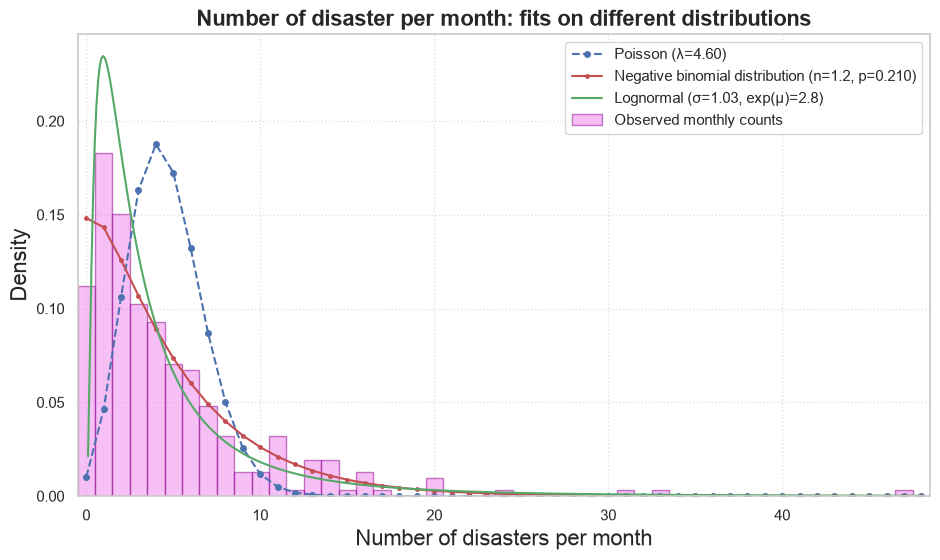

In [149]:
# FIT of MONTHLY DISASTER COUNTS
lambda_month = np.mean(monthly_counts)
var_month = np.var(monthly_counts, ddof = 1)
p = lambda_month / var_month if var_month > lambda_month else 0.5
n = (lambda_month**2) / (var_month - lambda_month) if var_month > lambda_month else 0.5

r_month = minimize(nll_nbinom, x0 = [n, p], args = (monthly_counts, ), bounds = [(1e-4, None), (1e-4, 0.9999)])
n_month, p_month = r_month.x

monthly_counts_pos = np.where(monthly_counts == 0, 0.5, monthly_counts)
shape_ln_month, _, scale_ln_month = stats.lognorm.fit(monthly_counts_pos, floc = 0)

print(f"Fitted Poisson: lambda = {lambda_month:.2f}")
print(f"Fitted Negative Binomial: n = {n_month:.2f}, p = {p_month:.4f}")
print(f"Fitted lognormal: shape = {shape_ln_month:.4f}, scale = {scale_ln_month:.2f}")

print(len(monthly_counts))

plt.figure(figsize = (11, 6))
# k_min = int(max(0, np.min(monthly_counts) - 5))
# k_max = int(np.max(monthly_counts) + 2)
k_min = 0
k_max = int(np.max(monthly_counts) + 1)
k_discrete = np.arange(k_min, k_max + 1)
k_cont = np.linspace(max(0.1, k_min), k_max, 500)
bins_month = np.arange(k_min - 0.5, k_max + 1.5, 1)

# adding all three fitted distributions
plt.plot(k_discrete, stats.poisson.pmf(k_discrete, mu = lambda_month), "b--", marker = "o", markersize = 4, label = f"Poisson (λ={lambda_month:.2f})")
plt.plot(k_discrete, stats.nbinom.pmf(k_discrete, n_month, p_month), "r-", marker = "o", markersize = 2.5, label = f"Negative binomial distribution (n={n_month:.1f}, p={p_month:.3f})")
plt.plot(k_cont, stats.lognorm.pdf(k_cont, shape_ln_month, 0, scale_ln_month), "g", label = f"Lognormal (σ={shape_ln_month:.2f}, exp(μ)={scale_ln_month:.1f})")

plt.hist(monthly_counts, bins = bins_month, density = True, alpha = 0.5, color = "violet", edgecolor = "darkmagenta", label = "Observed monthly counts")
plt.xlabel("Number of disasters per month", fontsize = 16)
plt.ylabel("Density", fontsize = 16)
plt.title("Number of disaster per month: fits on different distributions", fontweight = "bold", fontsize = 16)

plt.xlim(-0.5, k_max + 0.5)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.savefig(
    "plots/monthly_distribution.pdf",
    format="pdf",
    bbox_inches="tight", 
    pad_inches=0.05 
)

plt.show()

In [127]:
output_csv_path = "../Data/Results/CLEAN_disasters_europe.csv"
export_cols = [
    "DisNo.",
    "Country",
    "Subregion",
    "Disaster Type",
    "Start Year",
    "Start Month",
    "Start Date",
    "End Date",
    "event_duration",
    "Total Damage, Adjusted ('000 US$)"
]
df_events[export_cols].to_csv(output_csv_path, index=False)
